# EEG Eye State Classification with CNN

**عنوان پروژه:** طبقه بندی وضعیت چشم (باز/بسته) از روی سیگنال EEG با شبکه پیچشی یک بعدی (1D CNN)

دیتاست EEG Eye State از UCI: حدود 15 هزار نمونه، 14 کانال EEG و برچسب `eyeDetection` (0 = چشم باز، 1 = چشم بسته).

In [1]:
!pip install -q torch torchvision scikit-learn pandas matplotlib seaborn scipy


[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


## ۱. Import ها

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from scipy.io import arff
import time

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('PyTorch', torch.__version__, '| device:', DEVICE)

DATA_PATH = 'EEG Eye State.arff'   # اگه فایل جای دیگه ایه، مسیرش رو اینجا عوض کن
LABEL_COL = 'eyeDetection'
CLASS_NAMES = ['Open (0)', 'Closed (1)']

PyTorch 2.15.0 | device: cpu


## ۲. بارگذاری و بررسی داده

In [3]:
def load_eeg_data(filepath: str) -> pd.DataFrame:
    # ARFF رو میخونیم؛ ستون برچسب nominal هست و به صورت bytes (مثل b'0') برمیگرده، پس decode و int میکنیم
    raw, _ = arff.loadarff(filepath)
    df = pd.DataFrame(raw)
    df[LABEL_COL] = df[LABEL_COL].str.decode('utf-8').astype(np.int64)
    feature_cols = [c for c in df.columns if c != LABEL_COL]
    df[feature_cols] = df[feature_cols].astype(np.float32)
    return df

In [4]:
def explore_data(df: pd.DataFrame) -> None:
    feature_cols = [c for c in df.columns if c != LABEL_COL]
    print('ابعاد داده:', df.shape)
    print('تعداد کانال ها:', len(feature_cols), '->', feature_cols)
    print('مقدار گمشده:', int(df.isna().sum().sum()))
    display(df.describe().T)

    # 1) توزیع کلاس ها
    counts = df[LABEL_COL].value_counts().sort_index()
    print('\nتوزیع کلاس ها:'); print(pd.DataFrame({'count': counts, 'ratio': (counts / len(df)).round(3)}))
    fig, ax = plt.subplots(figsize=(5, 3.5))
    ax.bar(CLASS_NAMES, counts.values, color=['#F06595', '#A61E4D'])
    for i, v in enumerate(counts.values):
        ax.text(i, v, str(v), ha='center', va='bottom')
    ax.set_title('Class distribution'); ax.set_ylabel('Samples')
    plt.tight_layout(); plt.show()

    # 2) نمای کلی چند کانال اول در طول زمان (ناحیه نارنجی = چشم بسته)
    n_show = 4
    t = np.arange(len(df))
    closed = df[LABEL_COL].values == 1
    fig, axes = plt.subplots(n_show, 1, figsize=(14, 2.2 * n_show), sharex=True)
    for ax, ch in zip(axes, feature_cols[:n_show]):
        y = df[ch].values
        lo, hi = np.percentile(y, [0.5, 99.5])     # چند اسپایک خیلی بزرگ داریم؛ محور y رو محدود میکنیم که شکل سیگنال دیده بشه
        ax.plot(t, y, lw=0.5, color='#A61E4D')
        ax.fill_between(t, lo, hi, where=closed, color='#FFC2D9', alpha=0.6, step='mid')
        ax.set_ylim(lo, hi); ax.set_ylabel(ch)
    axes[0].set_title('First channels over time (pink = eyes closed)')
    axes[-1].set_xlabel('Sample index (time)')
    plt.tight_layout(); plt.show()

    # 3) نقطه های پرت: مقدار عادی سیگنال حدود 4000 تا 4600 ـه ولی max بعضی کانال ها خیلی بزرگتره
    print('\nبیشترین مقدار هر کانال (نقطه های پرت):')
    print(df[feature_cols].max().sort_values(ascending=False).head(6))

ابعاد داده: (14980, 15)
تعداد کانال ها: 14 -> ['AF3', 'F7', 'F3', 'FC5', 'T7', 'P7', 'O1', 'O2', 'P8', 'T8', 'FC6', 'F4', 'F8', 'AF4']
مقدار گمشده: 0


,count,mean,std,min,25%,50%,75%,max
AF3,14980.0,4321.917969,2492.072021,1030.770020,4280.509766,4294.359863,4311.790039,309231.000000
F7,14980.0,4009.767578,45.941673,2830.770020,3990.770020,4005.639893,4023.080078,7804.620117
F3,14980.0,4264.022461,44.428051,1040.000000,4250.259766,4262.560059,4270.770020,6880.509766
FC5,14980.0,4164.946289,5216.404785,2453.330078,4108.209961,4120.509766,4132.310059,642564.000000
T7,14980.0,4341.741211,34.738819,2089.739990,4331.790039,4338.970215,4347.180176,6474.359863
P7,14980.0,4644.022461,2924.789551,2768.209961,4611.790039,4617.950195,4626.669922,362564.000000
O1,14980.0,4110.399902,4600.926758,2086.149902,4057.949951,4070.260010,4083.590088,567179.000000
O2,14980.0,4616.057129,29.292604,4567.180176,4604.620117,4613.330078,4624.100098,7264.100098
P8,14980.0,4218.826660,2136.408447,1357.949951,4190.770020,4199.490234,4209.229980,265641.000000
T8,14980.0,4231.315918,38.050900,1816.410034,4220.509766,4229.229980,4239.490234,6674.359863



توزیع کلاس ها:
              count  ratio
eyeDetection              
0              8257  0.551
1              6723  0.449


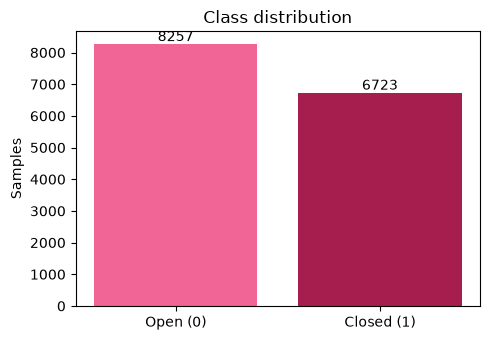

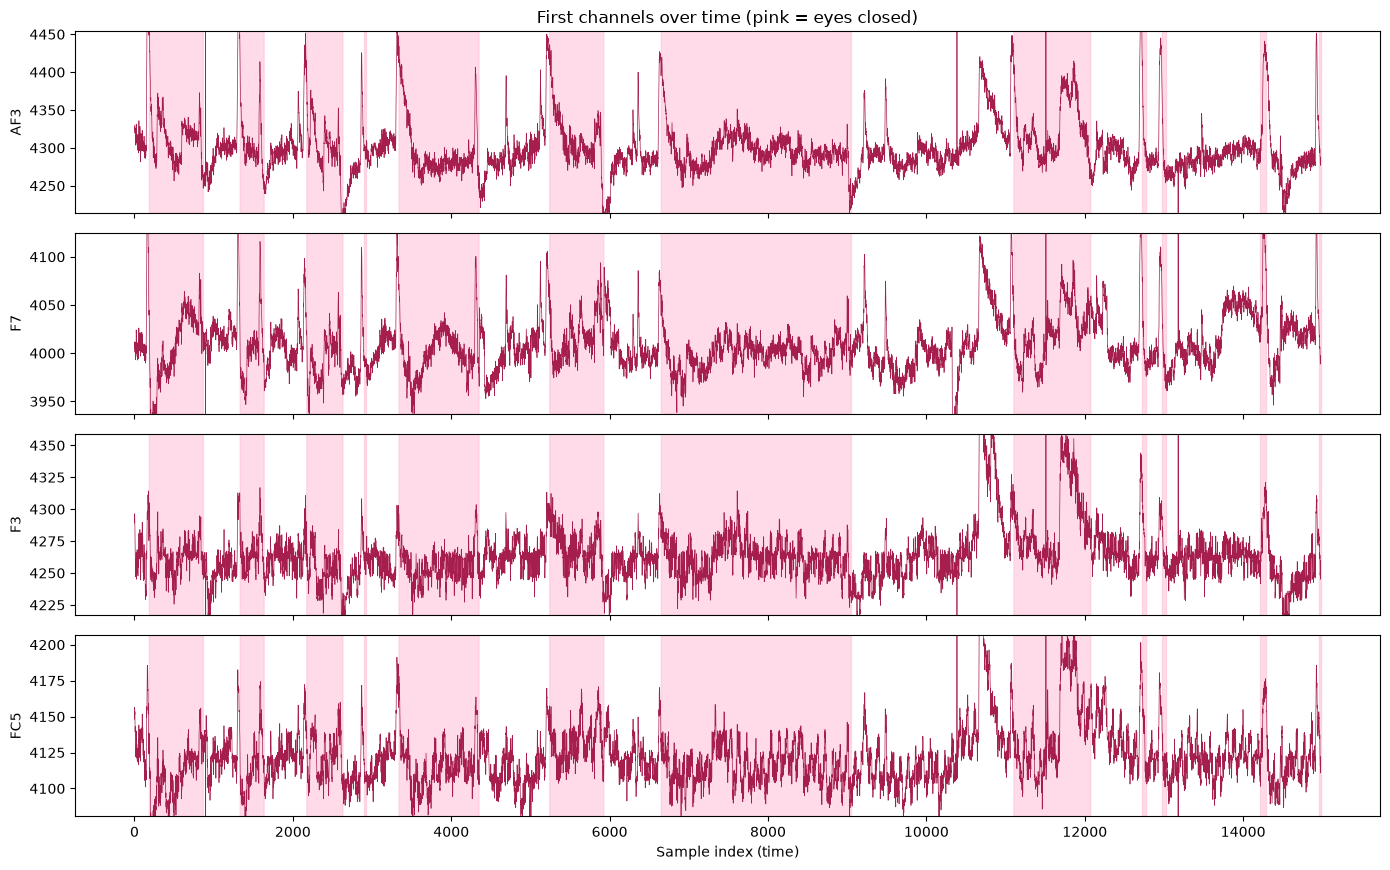


بیشترین مقدار هر کانال (نقطه های پرت):
AF4    715897.0
FC5    642564.0
O1     567179.0
P7     362564.0
AF3    309231.0
P8     265641.0
dtype: float32


In [5]:
df = load_eeg_data(DATA_PATH)
explore_data(df)

**نتیجه EDA:** کلاس ها تقریبا متعادلن. ولی تو چند کانال چند تا مقدار خیلی بزرگ (اسپایک سنسور) هست، مثلا تا 715 هزار در حالی که مقدار عادی حدود 4300 ـه. این چند نقطه انحراف معیار رو خیلی بزرگ میکنن، برای همین قبل از نرمال سازی باید حذف اثرشون کنیم (بخش بعد).

## ۳. پیش‌پردازش

**تقسیم زمانی:** چون نمونه های کنار هم تقریبا یکسانن، اگه تصادفی تقسیم کنیم نمونه های تقریبا تکراری هم تو آموزش میفتن هم تو تست و دقت به شکل غیر واقعی بالا میره (Data Leakage). پس داده رو به ترتیب زمان ثبت تقسیم میکنیم: 70% اول آموزش، 15% بعدی اعتبارسنجی، 15% آخر تست.

In [6]:
def chronological_split(df: pd.DataFrame, train_ratio: float=0.7, val_ratio: float=0.15):
    # بدون shuffle؛ فقط برش به ترتیب زمان
    n = len(df)
    train_end = int(n * train_ratio)
    val_end = int(n * (train_ratio + val_ratio))
    train_df = df.iloc[:train_end].reset_index(drop=True)
    val_df = df.iloc[train_end:val_end].reset_index(drop=True)
    test_df = df.iloc[val_end:].reset_index(drop=True)
    return train_df, val_df, test_df

**نرمال سازی:** `StandardScaler` فقط روی داده آموزش fit میشه و همون تبدیل روی val و test اعمال میشه.

قبلش مقادیر هر کانال رو با `np.clip` به یه بازه معقول محدود میکنیم (صدک 0.1 تا 99.9 داده آموزش). دلیلش اینه که چند تا اسپایک انحراف معیار بعضی کانال ها رو از حدود 15 به چند هزار میرسونن و بدون این کار اون کانال ها بعد از نرمال سازی تقریبا صاف (نزدیک صفر) میشن و برای مدل بی فایده میشن.

In [7]:
def normalize_features(train_df: pd.DataFrame, val_df: pd.DataFrame, test_df: pd.DataFrame):
    feature_cols = [c for c in train_df.columns if c != LABEL_COL]

    # بازه مجاز هر کانال فقط از روی داده آموزش
    low = np.percentile(train_df[feature_cols], 0.1, axis=0)
    high = np.percentile(train_df[feature_cols], 99.9, axis=0)

    scaler = StandardScaler()
    scaler.fit(np.clip(train_df[feature_cols], low, high))

    train_out, val_out, test_out = train_df.copy(), val_df.copy(), test_df.copy()
    for part in [train_out, val_out, test_out]:
        part[feature_cols] = scaler.transform(np.clip(part[feature_cols], low, high))
    return train_out, val_out, test_out

**پنجره لغزنده:** سیگنال پیوسته به قطعه های `window_size` نمونه ای (128 نمونه، حدود یک ثانیه با نرخ ~128Hz) خرد میشه. برچسب هر پنجره برچسب **آخرین نمونه** اونه؛ یعنی مدل با دیدن 128 نمونه گذشته وضعیت لحظه فعلی رو تشخیص میده.

پنجره ها با گام `step` جلو میرن (یه حلقه ساده روی نقطه شروع پنجره ها، بدون حلقه تودرتو). هر بخش (train/val/test) جدا پنجره بندی میشه که هیچ پنجره ای از مرز بخش ها رد نشه. خروجی به شکل `(N, window_size, channels)` ـه.

In [8]:
def create_windows(X: np.ndarray, y: np.ndarray, window_size: int = 128, step: int = 64) -> tuple[np.ndarray, np.ndarray]:
    # نقطه شروع هر پنجره: 0, step, 2*step, ...
    starts = range(0, len(X) - window_size + 1, step)
    X_win = np.array([X[s:s + window_size] for s in starts], dtype=np.float32)   # (N, window, C)
    y_win = np.array([y[s + window_size - 1] for s in starts], dtype=np.int64)   # برچسب آخرین نمونه هر پنجره
    return X_win, y_win

In [9]:
def make_dataloaders(X: np.ndarray, y: np.ndarray, batch_size: int = 64, shuffle: bool = False) -> DataLoader:
    dataset = TensorDataset(torch.from_numpy(X).float(), torch.from_numpy(y).long())
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)

### اجرای پیش پردازش

In [10]:
WINDOW_SIZE = 128
STEP = 16          # با step=64 فقط حدود 160 پنجره آموزشی داشتیم؛ 16 تعداد پنجره ها رو 4 برابر میکنه
BATCH_SIZE = 64

train_df, val_df, test_df = chronological_split(df, train_ratio=0.7, val_ratio=0.15)
for name, part in [('train', train_df), ('val', val_df), ('test', test_df)]:
    print(f'{name:5s}: {len(part):6d} samples | closed ratio = {part[LABEL_COL].mean():.3f}')

train_n, val_n, test_n = normalize_features(train_df, val_df, test_df)
feature_cols = [c for c in df.columns if c != LABEL_COL]
NUM_CHANNELS = len(feature_cols)
print('\nبعد از نرمال سازی، میانگین train (باید ~0 باشه):', train_n[feature_cols].values.mean(axis=0).round(2)[:5])
print('بعد از نرمال سازی، انحراف معیار train (باید ~1 باشه):', train_n[feature_cols].values.std(axis=0).round(2)[:5])

def to_xy(part):
    return part[feature_cols].values.astype(np.float32), part[LABEL_COL].values.astype(np.int64)

X_train, y_train = create_windows(*to_xy(train_n), window_size=WINDOW_SIZE, step=STEP)
X_val, y_val = create_windows(*to_xy(val_n), window_size=WINDOW_SIZE, step=STEP)
X_test, y_test = create_windows(*to_xy(test_n), window_size=WINDOW_SIZE, step=STEP)
print()
for name, Xw, yw in [('train', X_train, y_train), ('val', X_val, y_val), ('test', X_test, y_test)]:
    print(f'{name:5s} windows: X={Xw.shape} | y={yw.shape} | closed ratio={yw.mean():.3f}')

train_loader = make_dataloaders(X_train, y_train, batch_size=BATCH_SIZE, shuffle=True)   # تقسیم زمانی قبلا انجام شده، shuffle داخل train مشکلی نداره
val_loader = make_dataloaders(X_val, y_val, batch_size=256, shuffle=False)
test_loader = make_dataloaders(X_test, y_test, batch_size=256, shuffle=False)

xb, yb = next(iter(train_loader))
print('\nیه batch:', tuple(xb.shape), tuple(yb.shape))

train:  10486 samples | closed ratio = 0.531
val  :   2247 samples | closed ratio = 0.434
test :   2247 samples | closed ratio = 0.081

بعد از نرمال سازی، میانگین train (باید ~0 باشه): [-0. -0. -0.  0.  0.]
بعد از نرمال سازی، انحراف معیار train (باید ~1 باشه): [1. 1. 1. 1. 1.]

train windows: X=(648, 128, 14) | y=(648,) | closed ratio=0.537
val   windows: X=(133, 128, 14) | y=(133,) | closed ratio=0.459
test  windows: X=(133, 128, 14) | y=(133,) | closed ratio=0.068

یه batch: (64, 128, 14) (64,)


**نکته:** چون تقسیم زمانیه، توزیع کلاس ها تو بخش ها یکسان نیست (مخصوصا تو 15% آخر ضبط بیشتر نمونه ها چشم بازن). این واقعیت داده ست و نباید با shuffle "درستش" کنیم؛ فقط باید موقع ارزیابی به جای accuracy تنها، به precision/recall/F1 هر کلاس هم نگاه کنیم.

## ۴. تعریف مدل CNN

سه بلوک `Conv1d → BatchNorm1d → ReLU → MaxPool1d` که هر کدوم طول زمانی رو نصف و تعداد فیلترها رو بیشتر میکنن (128 → 64 → 32 → 16)، بعد Flatten و دو لایه `Linear`. ورودی به شکل `(batch, window, channels)` میاد و تو `forward` با `permute` به `(batch, channels, window)` تبدیل میشه، چون `Conv1d` کانال ها رو تو بعد دوم میخواد.

In [11]:
class EEG_CNN(nn.Module):
    def __init__(self, num_channels: int = 14, window_size: int = 128):
        super().__init__()

        def conv_block(c_in, c_out, k):
            return nn.Sequential(
                nn.Conv1d(c_in, c_out, kernel_size=k, padding=k // 2),
                nn.BatchNorm1d(c_out),
                nn.ReLU(inplace=True),
                nn.MaxPool1d(kernel_size=2),
            )

        self.features = nn.Sequential(
            conv_block(num_channels, 32, 7),
            conv_block(32, 64, 5),
            conv_block(64, 128, 3),
        )
        flat_dim = 128 * (window_size // 8)       # سه بار MaxPool با kernel=2
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(flat_dim, 64),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(64, 2),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # (batch, window, channels) -> (batch, channels, window)
        x = x.permute(0, 2, 1)
        x = self.features(x)
        return self.classifier(x)

In [12]:
_m = EEG_CNN(num_channels=NUM_CHANNELS, window_size=WINDOW_SIZE)
print(_m)
print('trainable params:', sum(p.numel() for p in _m.parameters() if p.requires_grad))
with torch.no_grad():
    print('output shape:', tuple(_m(xb).shape))
del _m

EEG_CNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv1d(14, 32, kernel_size=(7,), stride=(1,), padding=(3,))
      (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv1d(32, 64, kernel_size=(5,), stride=(1,), padding=(2,))
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,))
      (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (classifi

## ۵. آموزش مدل

In [13]:
def train_one_epoch(model: nn.Module, loader: DataLoader, optimizer: torch.optim.Optimizer, criterion: nn.Module) -> tuple[float, float]:
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * yb.size(0)
        correct += (logits.argmax(dim=1) == yb).sum().item()
        total += yb.size(0)
    return total_loss / total, correct / total

@torch.no_grad()
def evaluate(model: nn.Module, loader: DataLoader, criterion: nn.Module) -> tuple[float, float]:
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        logits = model(xb)
        total_loss += criterion(logits, yb).item() * yb.size(0)
        correct += (logits.argmax(dim=1) == yb).sum().item()
        total += yb.size(0)
    return total_loss / total, correct / total

In [14]:
def train_model(model: nn.Module, train_loader: DataLoader, val_loader: DataLoader, num_epochs: int = 25, lr: float = 1e-3) -> dict:
    # تعداد epoch ثابته و هیچ Early Stopping ای نداریم؛ فقط تاریخچه ثبت میشه
    model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    start = time.time()
    for epoch in range(1, num_epochs + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, criterion)
        va_loss, va_acc = evaluate(model, val_loader, criterion)
        history['train_loss'].append(tr_loss); history['train_acc'].append(tr_acc)
        history['val_loss'].append(va_loss); history['val_acc'].append(va_acc)
        print(f'Epoch {epoch:02d}/{num_epochs} | train loss {tr_loss:.4f} acc {tr_acc:.4f} '
              f'| val loss {va_loss:.4f} acc {va_acc:.4f}')
    print(f'زمان آموزش: {time.time() - start:.1f} ثانیه')
    return history

In [15]:
NUM_EPOCHS = 40
torch.manual_seed(SEED)
model = EEG_CNN(num_channels=NUM_CHANNELS, window_size=WINDOW_SIZE)
history = train_model(model, train_loader, val_loader, num_epochs=NUM_EPOCHS, lr=1e-3)

Epoch 01/40 | train loss 0.6571 acc 0.6219 | val loss 1.0162 acc 0.4286
Epoch 02/40 | train loss 0.3322 acc 0.8827 | val loss 3.3264 acc 0.4060
Epoch 03/40 | train loss 0.1532 acc 0.9352 | val loss 5.3231 acc 0.3985
Epoch 04/40 | train loss 0.0913 acc 0.9769 | val loss 4.7110 acc 0.4286
Epoch 05/40 | train loss 0.0502 acc 0.9846 | val loss 6.7249 acc 0.4060
Epoch 06/40 | train loss 0.0602 acc 0.9815 | val loss 8.9002 acc 0.4436
Epoch 07/40 | train loss 0.0556 acc 0.9846 | val loss 7.8944 acc 0.4060
Epoch 08/40 | train loss 0.0364 acc 0.9892 | val loss 7.2369 acc 0.4060
Epoch 09/40 | train loss 0.0230 acc 0.9954 | val loss 7.3871 acc 0.4135
Epoch 10/40 | train loss 0.0128 acc 0.9954 | val loss 7.6398 acc 0.4135
Epoch 11/40 | train loss 0.0194 acc 0.9954 | val loss 8.3554 acc 0.4135
Epoch 12/40 | train loss 0.0439 acc 0.9815 | val loss 8.1055 acc 0.4211
Epoch 13/40 | train loss 0.0491 acc 0.9846 | val loss 9.8477 acc 0.4211
Epoch 14/40 | train loss 0.0626 acc 0.9722 | val loss 8.9129 acc

## ۶. رسم منحنی‌های آموزش

In [16]:
def plot_training_history(history: dict) -> None:
    epochs = np.arange(1, len(history['train_loss']) + 1)
    best_ep = int(np.argmin(history['val_loss'])) + 1   # فقط برای علامت گذاری روی نمودار، نه توقف آموزش

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    axes[0].plot(epochs, history['train_loss'], 'o-', ms=3, color='#A61E4D', label='Train loss')
    axes[0].plot(epochs, history['val_loss'], 'o-', ms=3, color='#F06595', label='Validation loss')
    axes[0].axvline(best_ep, ls='--', c='gray', label=f'Min val loss (epoch {best_ep})')
    axes[0].set_title('Loss'); axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Cross-entropy')
    axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(epochs, history['train_acc'], 'o-', ms=3, color='#A61E4D', label='Train acc')
    axes[1].plot(epochs, history['val_acc'], 'o-', ms=3, color='#F06595', label='Validation acc')
    axes[1].axvline(best_ep, ls='--', c='gray')
    axes[1].set_title('Accuracy'); axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
    axes[1].legend(); axes[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()

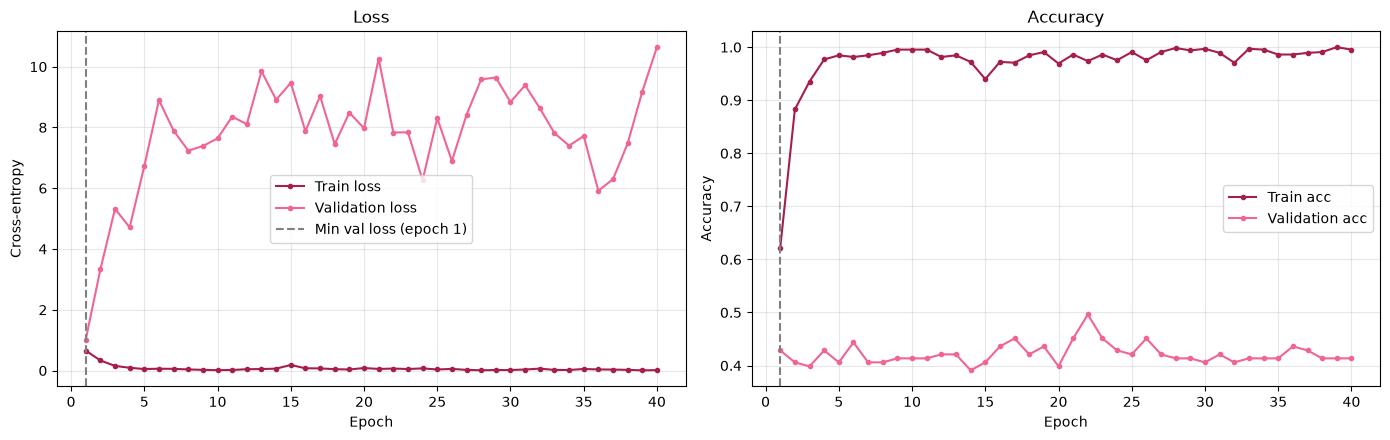

کمترین val loss: 1.0162 در epoch 1
از epoch 1 تا 40: train loss 0.6571 → 0.0134  |  val loss 1.0162 → 10.6416
فاصله val - train: در epoch 1 = 0.3592 ، در آخر = 10.6282


In [17]:
plot_training_history(history)

tl, vl = np.array(history['train_loss']), np.array(history['val_loss'])
best_ep = int(np.argmin(vl)) + 1
print(f'کمترین val loss: {vl[best_ep-1]:.4f} در epoch {best_ep}')
print(f'از epoch {best_ep} تا {len(vl)}: train loss {tl[best_ep-1]:.4f} → {tl[-1]:.4f}  |  val loss {vl[best_ep-1]:.4f} → {vl[-1]:.4f}')
print(f'فاصله val - train: در epoch {best_ep} = {vl[best_ep-1]-tl[best_ep-1]:.4f} ، در آخر = {vl[-1]-tl[-1]:.4f}')

**تشخیص بیش برازش از روی نمودار:** خطای آموزش از 0.66 تا نزدیک صفر (0.01) پایین میاد و دقت آموزش به حدود 99% میرسه، ولی خطای اعتبارسنجی از همون **epoch 1** (کمترین مقدار، حدود 1.02) فقط بالا میره و آخرش به بیشتر از 10 میرسه. دقت اعتبارسنجی هم تو کل آموزش بین 39% تا 50% میمونه، یعنی نزدیک حدس شانسی. پس **بیش برازش تقریبا از همون epoch های اول شروع میشه** (خط چین عمودی نقطه کمترین val loss رو نشون میده) و فاصله دو منحنی تا آخر مدام بیشتر میشه: شبکه خیلی سریع داده آموزش رو حفظ میکنه و چیزی که یاد میگیره به داده های بعدی تعمیم پیدا نمیکنه.

دلیل احتمالی: داده آموزش فقط 648 پنجره داره که خیلی روی هم میفتن، و چون تقسیم زمانیه، بخش های بعدی ضبط (val و test) با بخش اول فرق دارن. این هم نتیجه همون چیزیه که تقسیم زمانی قراره نشون بده؛ اگه تصادفی تقسیم کرده بودیم، به خاطر نشت داده دقت بالا و گمراه کننده میشد.

## ۷. ارزیابی نهایی

In [18]:
@torch.no_grad()
def get_all_predictions(model: nn.Module, loader: DataLoader) -> tuple[np.ndarray, np.ndarray]:
    model.eval()
    preds, labels = [], []
    for xb, yb in loader:
        logits = model(xb.to(DEVICE))
        preds.append(logits.argmax(dim=1).cpu().numpy())
        labels.append(yb.numpy())
    return np.concatenate(preds), np.concatenate(labels)

def plot_confusion_matrix(y_true: np.ndarray, y_pred: np.ndarray) -> None:
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(5, 4.5))
    sns.heatmap(cm, annot=True, fmt='d', cmap=sns.light_palette('#D6336C', as_cmap=True), cbar=False,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_xlabel('Predicted label'); ax.set_ylabel('True label')
    ax.set_title('Confusion Matrix — Test set')
    plt.tight_layout(); plt.show()

Test loss: 1.5879 | Test accuracy: 0.6241

              precision    recall  f1-score   support

    Open (0)     0.9302    0.6452    0.7619       124
  Closed (1)     0.0638    0.3333    0.1071         9

    accuracy                         0.6241       133
   macro avg     0.4970    0.4892    0.4345       133
weighted avg     0.8716    0.6241    0.7176       133



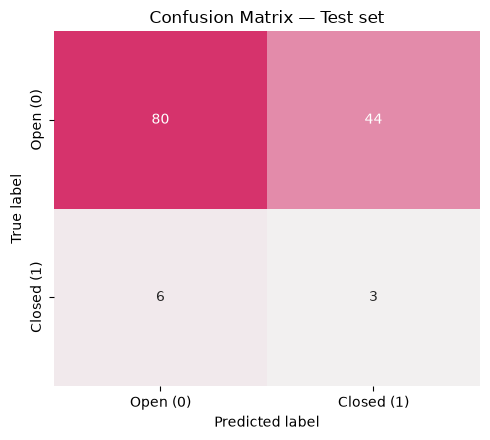

In [19]:
criterion = nn.CrossEntropyLoss()
test_loss, test_acc = evaluate(model, test_loader, criterion)
print(f'Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.4f}\n')

y_pred, y_true = get_all_predictions(model, test_loader)
print(classification_report(y_true, y_pred, labels=[0, 1], target_names=CLASS_NAMES, digits=4, zero_division=0))
plot_confusion_matrix(y_true, y_pred)

## جمع بندی

- داده ها به ترتیب زمانی به آموزش/اعتبارسنجی/تست تقسیم شدن تا نشت داده پیش نیاد؛ محدود کردن نقطه های پرت و `StandardScaler` فقط با آمار داده آموزش انجام شدن.
- پنجره های 128 نمونه ای برای هر بخش جدا ساخته شدن و هیچ پنجره ای از مرز بخش ها رد نشد.
- مدل `EEG_CNN` (سه بلوک `Conv1d/BatchNorm1d/MaxPool1d` + دو لایه `Linear`) برای تعداد epoch ثابت و بدون Early Stopping آموزش دید. از روی نمودار loss، بیش برازش از همون epoch های اول شروع شد (train acc حدود 99%، val acc حدود 40%).
- نتیجه تست: دقت 62%، ولی recall کلاس "چشم بسته" فقط 33% و F1 اون کلاس حدود 0.11 ـه. تو 15% آخر داده فقط حدود 7% پنجره ها چشم بسته ست (9 از 133 پنجره)، پس accuracy به تنهایی گول زنندست و باید به recall و F1 هر کلاس نگاه کرد. مدل روی داده های آینده خوب تعمیم پیدا نکرده، که با بیش برازش شدید و کم بودن داده آموزش تو تقسیم زمانی جوره.